In [1]:
import cv2

Shape: (512, 512, 3)
Data Type: uint8


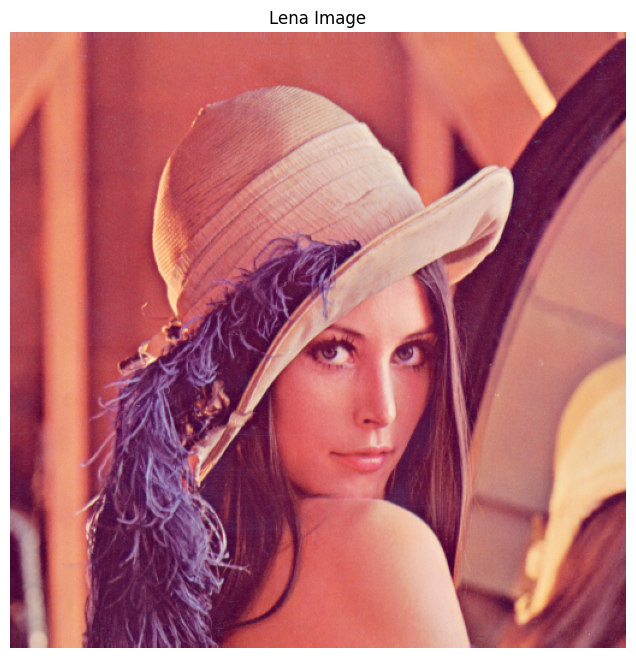

In [5]:
import matplotlib.pyplot as plt

# 이미지 로드
img = cv2.imread('lena.png')

# 이미지 정보 출력
print(f"Shape: {img.shape}")
print(f"Data Type: {img.dtype}")

# BGR을 RGB로 변환 (OpenCV는 BGR 포맷 사용)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 이미지 출력
plt.figure(figsize=(8, 8))
plt.imshow(img_rgb)
plt.title('Lena Image')
plt.axis('off')
plt.show()

Grayscale Shape: (512, 512)
Grayscale Data Type: uint8


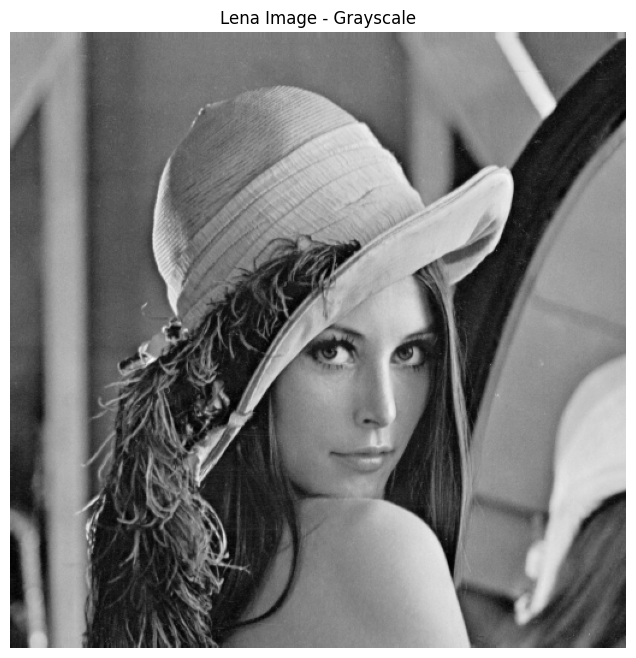

In [6]:
# 이미지를 Grayscale로 변환
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Grayscale 이미지 정보 출력
print(f"Grayscale Shape: {img_gray.shape}")
print(f"Grayscale Data Type: {img_gray.dtype}")

# Grayscale 이미지 출력
plt.figure(figsize=(8, 8))
plt.imshow(img_gray, cmap='gray')
plt.title('Lena Image - Grayscale')
plt.axis('off')
plt.show()

Resized Shape: (256, 256, 3)


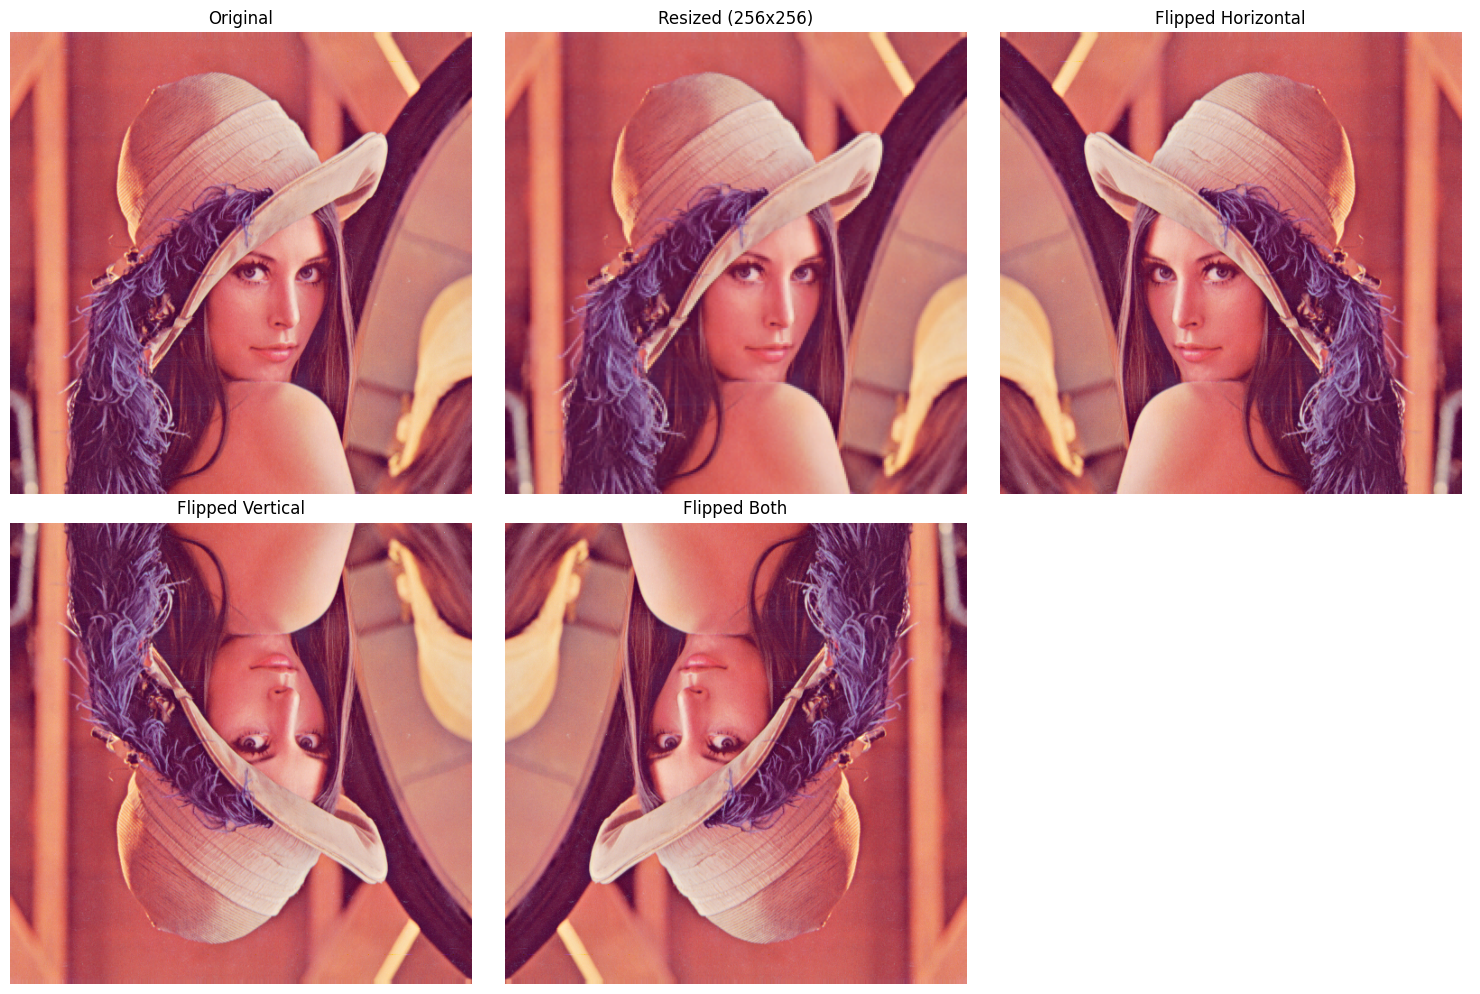

In [7]:
# 이미지 Resizing
resized_img = cv2.resize(img, (256, 256))
print(f"Resized Shape: {resized_img.shape}")

# 이미지 Flipping
flipped_horizontal = cv2.flip(img, 1)  # 수평 뒤집기
flipped_vertical = cv2.flip(img, 0)    # 수직 뒤집기
flipped_both = cv2.flip(img, -1)       # 양방향 뒤집기

# 결과 이미지 출력
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# 원본 이미지 (RGB 변환)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
axes[0, 0].imshow(img_rgb)
axes[0, 0].set_title('Original')
axes[0, 0].axis('off')

# Resized 이미지
resized_rgb = cv2.cvtColor(resized_img, cv2.COLOR_BGR2RGB)
axes[0, 1].imshow(resized_rgb)
axes[0, 1].set_title('Resized (256x256)')
axes[0, 1].axis('off')

# 수평 뒤집기
flipped_h_rgb = cv2.cvtColor(flipped_horizontal, cv2.COLOR_BGR2RGB)
axes[0, 2].imshow(flipped_h_rgb)
axes[0, 2].set_title('Flipped Horizontal')
axes[0, 2].axis('off')

# 수직 뒤집기
flipped_v_rgb = cv2.cvtColor(flipped_vertical, cv2.COLOR_BGR2RGB)
axes[1, 0].imshow(flipped_v_rgb)
axes[1, 0].set_title('Flipped Vertical')
axes[1, 0].axis('off')

# 양방향 뒤집기
flipped_both_rgb = cv2.cvtColor(flipped_both, cv2.COLOR_BGR2RGB)
axes[1, 1].imshow(flipped_both_rgb)
axes[1, 1].set_title('Flipped Both')
axes[1, 1].axis('off')

# 마지막 칸 비우기
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

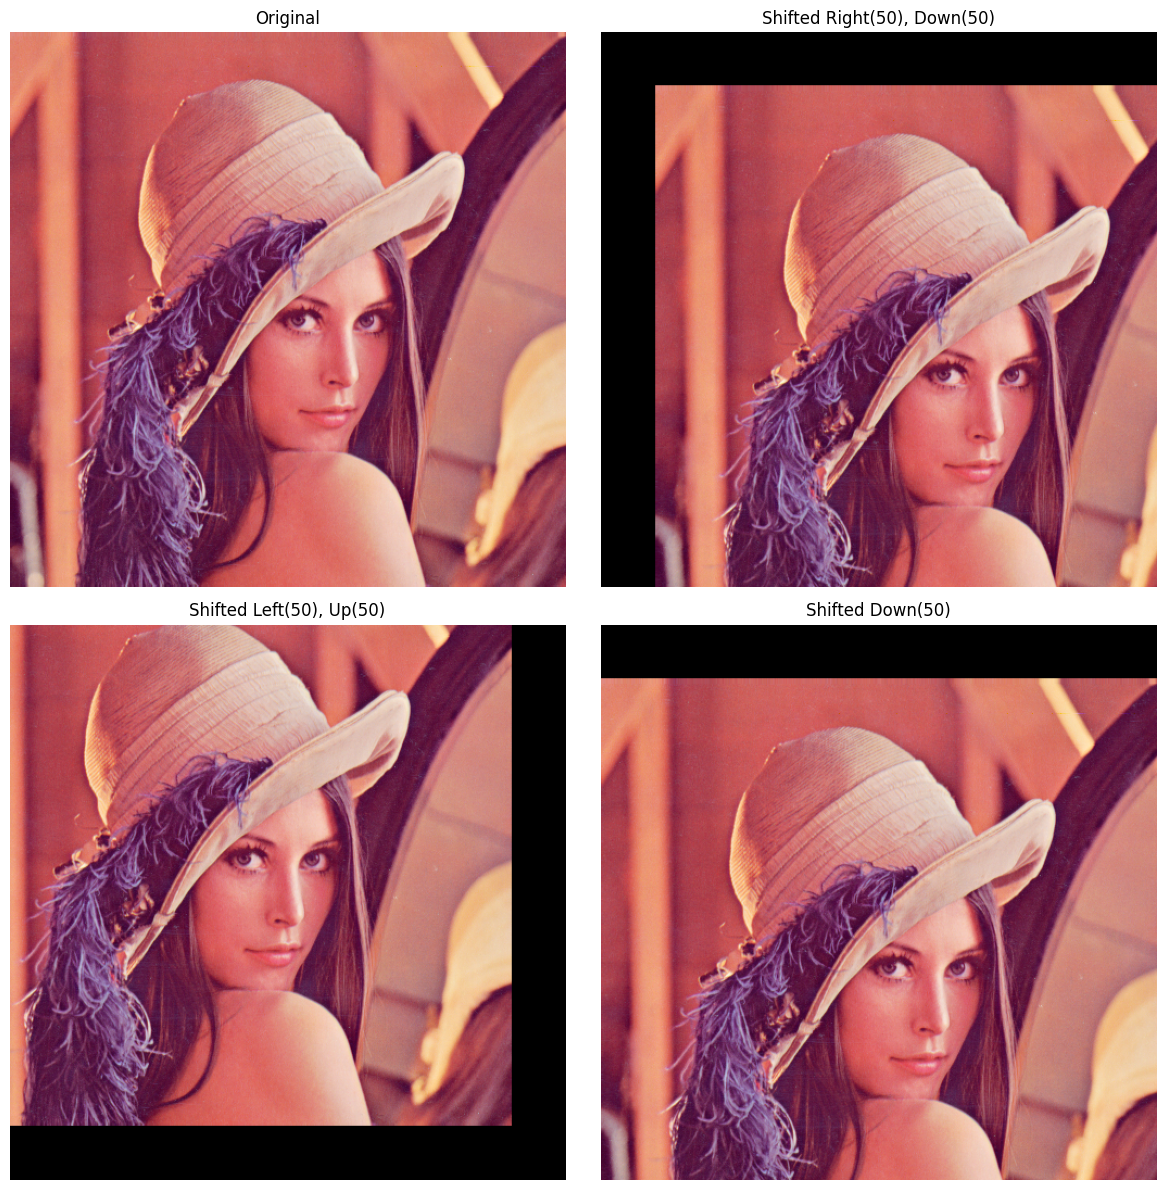

In [8]:
# 이미지 Shift (평행이동)
height, width = img.shape[:2]

# Shift 파라미터
shift_x = 50  # 오른쪽으로 50 픽셀
shift_y = 50  # 아래로 50 픽셀

# Affine 변환 행렬 생성
M_shift_right = cv2.getRotationMatrix2D((width//2, height//2), 0, 1)
M_shift_right[0, 2] = shift_x
M_shift_right[1, 2] = shift_y

M_shift_left = cv2.getRotationMatrix2D((width//2, height//2), 0, 1)
M_shift_left[0, 2] = -shift_x
M_shift_left[1, 2] = -shift_y

M_shift_down = cv2.getRotationMatrix2D((width//2, height//2), 0, 1)
M_shift_down[0, 2] = 0
M_shift_down[1, 2] = shift_y

# Shift 적용
shifted_right = cv2.warpAffine(img, M_shift_right, (width, height))
shifted_left = cv2.warpAffine(img, M_shift_left, (width, height))
shifted_down = cv2.warpAffine(img, M_shift_down, (width, height))

# 결과 이미지 출력
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

# 원본 이미지
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
axes[0, 0].imshow(img_rgb)
axes[0, 0].set_title('Original')
axes[0, 0].axis('off')

# 오른쪽 아래로 Shift
shifted_right_rgb = cv2.cvtColor(shifted_right, cv2.COLOR_BGR2RGB)
axes[0, 1].imshow(shifted_right_rgb)
axes[0, 1].set_title(f'Shifted Right({shift_x}), Down({shift_y})')
axes[0, 1].axis('off')

# 왼쪽 위로 Shift
shifted_left_rgb = cv2.cvtColor(shifted_left, cv2.COLOR_BGR2RGB)
axes[1, 0].imshow(shifted_left_rgb)
axes[1, 0].set_title(f'Shifted Left({shift_x}), Up({shift_y})')
axes[1, 0].axis('off')

# 아래로 Shift
shifted_down_rgb = cv2.cvtColor(shifted_down, cv2.COLOR_BGR2RGB)
axes[1, 1].imshow(shifted_down_rgb)
axes[1, 1].set_title(f'Shifted Down({shift_y})')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

(100,100) 위치부터 10개 픽셀을 흰색으로 설정 완료


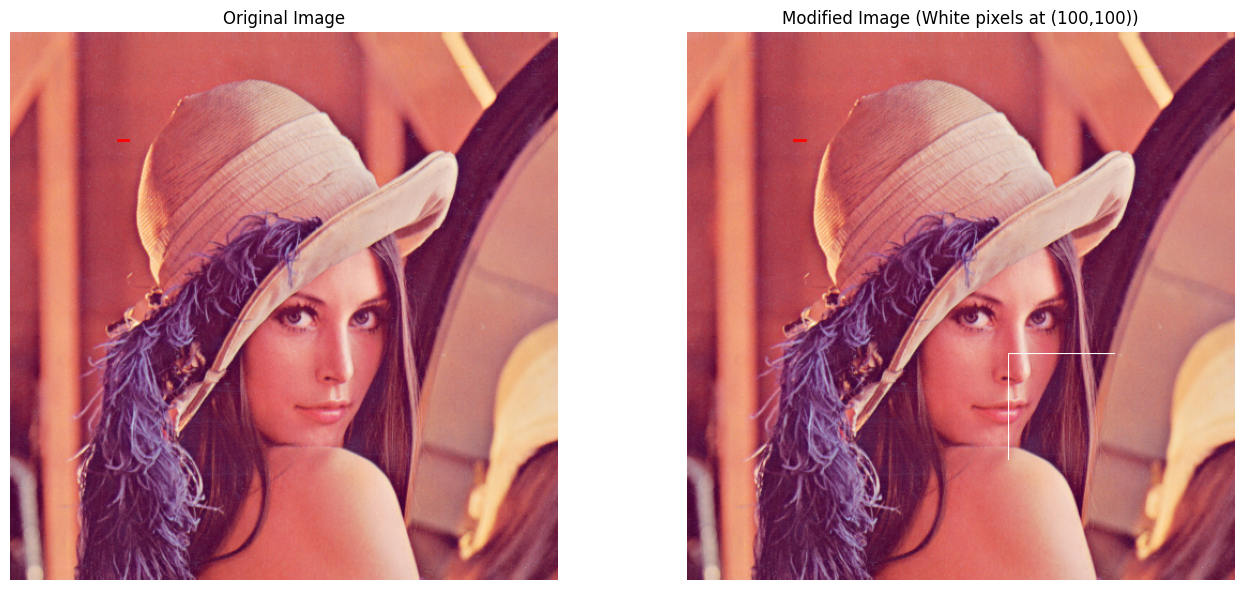

Modified pixels: [[ 78  68 178]
 [ 73  69 178]
 [ 84  70 174]
 [ 79  68 177]
 [ 77  71 174]
 [ 80  73 184]
 [ 74  71 184]
 [ 85  78 190]
 [ 86  76 183]
 [ 79  80 180]]


In [14]:
# (100,100) 위치부터 10개 픽셀을 흰색(BGR: 255,255,255)으로 설정
img_modified = img.copy()

# (100,100)부터 10개 픽셀 설정 (수평 방향)
for i in range(100):
    img_modified[300+i, 300] = [255, 255, 255]  # BGR 포맷: 흰색
    img_modified[300, 300+i] = [255, 255, 255]  # BGR 포맷: 흰색

print("(100,100) 위치부터 10개 픽셀을 흰색으로 설정 완료")

# 원본과 수정된 이미지 비교
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 원본 이미지
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
axes[0].imshow(img_rgb)
axes[0].set_title('Original Image')
axes[0].plot([100, 110], [100, 100], 'r-', linewidth=2)  # 수정 위치 표시
axes[0].axis('off')

# 수정된 이미지
img_modified_rgb = cv2.cvtColor(img_modified, cv2.COLOR_BGR2RGB)
axes[1].imshow(img_modified_rgb)
axes[1].set_title('Modified Image (White pixels at (100,100))')
axes[1].plot([100, 110], [100, 100], 'r-', linewidth=2)  # 수정 위치 표시
axes[1].axis('off')

plt.tight_layout()
plt.show()

# 수정된 픽셀 값 확인
print(f"Modified pixels: {img_modified[100, 100:110]}")

In [16]:
drawing = False
ix, iy = -1, -1
shape_type = 0
img_canvas = img.copy()

def draw(event, x, y, flags, param):
    global drawing, ix, iy, shape_type, img_canvas
    
    if event == cv2.EVENT_LBUTTONDOWN:
        drawing = True
        ix, iy = x, y
    
    elif event == cv2.EVENT_MOUSEMOVE:
        if drawing:
            img_temp = img_canvas.copy()
            if shape_type == 0:
                cv2.rectangle(img_temp, (ix, iy), (x, y), (0, 255, 0), 2)
            elif shape_type == 1:
                cv2.line(img_temp, (ix, iy), (x, y), (0, 0, 255), 2)
            elif shape_type == 2:
                cv2.arrowedLine(img_temp, (ix, iy), (x, y), (255, 0, 0), 2)
            
            cv2.imshow('Drawing', img_temp)
    
    elif event == cv2.EVENT_LBUTTONUP:
        drawing = False
        if shape_type == 0:
            cv2.rectangle(img_canvas, (ix, iy), (x, y), (0, 255, 0), 2)
        elif shape_type == 1:
            cv2.line(img_canvas, (ix, iy), (x, y), (0, 0, 255), 2)
        elif shape_type == 2:
            cv2.arrowedLine(img_canvas, (ix, iy), (x, y), (255, 0, 0), 2)
        
        cv2.imshow('Drawing', img_canvas)

cv2.namedWindow('Drawing')
cv2.setMouseCallback('Drawing', draw)

print("Rectangle: r, Line: l, Arrowedline: a, Clear: c, Quit: q")
cv2.imshow('Drawing', img_canvas)

for i in range(100):
    key = cv2.waitKey(1) & 0xFF
    
    if key == ord('r'):
        shape_type = 0
        print("Rectangle mode")
    elif key == ord('l'):
        shape_type = 1
        print("Line mode")
    elif key == ord('a'):
        shape_type = 2
        print("Arrowedline mode")
    elif key == ord('c'):
        img_canvas = img.copy()
        cv2.imshow('Drawing', img_canvas)
        print("Canvas cleared")
    elif key == ord('q'):
        break

cv2.destroyAllWindows()
print("Drawing completed")

Rectangle: r, Line: l, Arrowedline: a, Clear: c, Quit: q
Drawing completed
Drawing completed
